In [1]:
import json, glob, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = "../data/realAWSCloudwatch"
files = sorted(glob.glob(f"{DATA_DIR}/*.csv"))
print(len(files), "files")
for f in files:
    print(os.path.basename(f))

17 files
ec2_cpu_utilization_24ae8d.csv
ec2_cpu_utilization_53ea38.csv
ec2_cpu_utilization_5f5533.csv
ec2_cpu_utilization_77c1ca.csv
ec2_cpu_utilization_825cc2.csv
ec2_cpu_utilization_ac20cd.csv
ec2_cpu_utilization_c6585a.csv
ec2_cpu_utilization_fe7f93.csv
ec2_disk_write_bytes_1ef3de.csv
ec2_disk_write_bytes_c0d644.csv
ec2_network_in_257a54.csv
ec2_network_in_5abac7.csv
elb_request_count_8c0756.csv
grok_asg_anomaly.csv
iio_us-east-1_i-a2eb1cd9_NetworkIn.csv
rds_cpu_utilization_cc0c53.csv
rds_cpu_utilization_e47b3b.csv


In [2]:
with open("../data/labels/combined_windows.json") as f:
    windows = json.load(f)

aws_windows = {k: v for k, v in windows.items() if k.startswith("realAWSCloudwatch/")}
print(len(aws_windows), "files have labeled windows")
for k, v in aws_windows.items():
    print(k.split("/")[1], "->", len(v), "anomaly window(s)")

17 files have labeled windows
ec2_cpu_utilization_24ae8d.csv -> 2 anomaly window(s)
ec2_cpu_utilization_53ea38.csv -> 2 anomaly window(s)
ec2_cpu_utilization_5f5533.csv -> 2 anomaly window(s)
ec2_cpu_utilization_77c1ca.csv -> 1 anomaly window(s)
ec2_cpu_utilization_825cc2.csv -> 1 anomaly window(s)
ec2_cpu_utilization_ac20cd.csv -> 1 anomaly window(s)
ec2_cpu_utilization_c6585a.csv -> 0 anomaly window(s)
ec2_cpu_utilization_fe7f93.csv -> 3 anomaly window(s)
ec2_disk_write_bytes_1ef3de.csv -> 1 anomaly window(s)
ec2_disk_write_bytes_c0d644.csv -> 3 anomaly window(s)
ec2_network_in_257a54.csv -> 1 anomaly window(s)
ec2_network_in_5abac7.csv -> 2 anomaly window(s)
elb_request_count_8c0756.csv -> 2 anomaly window(s)
grok_asg_anomaly.csv -> 3 anomaly window(s)
iio_us-east-1_i-a2eb1cd9_NetworkIn.csv -> 2 anomaly window(s)
rds_cpu_utilization_cc0c53.csv -> 2 anomaly window(s)
rds_cpu_utilization_e47b3b.csv -> 2 anomaly window(s)


In [7]:
name = os.path.basename(files[2])
df = pd.read_csv(f"{DATA_DIR}/{name}", parse_dates=["timestamp"])
print(name)
print(df.shape)
df.head()

ec2_cpu_utilization_5f5533.csv
(4032, 2)


,timestamp,value
0,2014-02-14 14:27:00,51.846
1,2014-02-14 14:32:00,44.508
2,2014-02-14 14:37:00,41.244
3,2014-02-14 14:42:00,48.568
4,2014-02-14 14:47:00,46.714


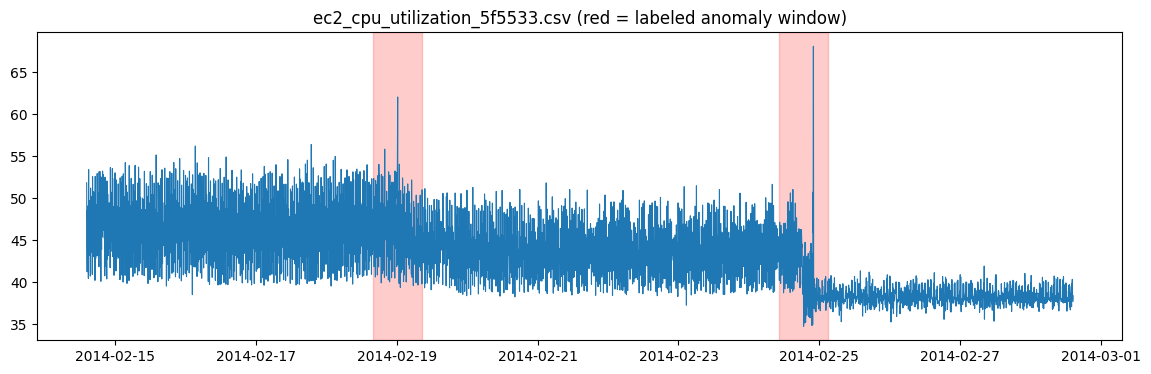

In [8]:
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(df["timestamp"], df["value"], linewidth=0.8)
for start, end in aws_windows.get(f"realAWSCloudwatch/{name}", []):
    ax.axvspan(pd.to_datetime(start), pd.to_datetime(end), color="red", alpha=0.2)
ax.set_title(f"{name} (red = labeled anomaly window)")
plt.show()


In [9]:
print(df["value"].describe())
print("Missing values:", df["value"].isnull().sum())
print("Time between readings:", df["timestamp"].diff().mode()[0])

count    4032.000000
mean       43.110372
std         4.303565
min        34.766000
25%        39.296000
50%        42.918000
75%        46.006000
max        68.092000
Name: value, dtype: float64
Missing values: 0
Time between readings: 0 days 00:05:00


In [10]:
rows = []
for f in files:
    n = os.path.basename(f)
    d = pd.read_csv(f, parse_dates=["timestamp"])
    inside = np.zeros(len(d), dtype=bool)
    for s, e in aws_windows.get(f"realAWSCloudwatch/{n}", []):
        inside |= (d["timestamp"] >= pd.to_datetime(s)) & (d["timestamp"] <= pd.to_datetime(e))
    rows.append({"file": n, "points": len(d),
                 "anomaly_points": int(inside.sum()),
                 "pct": round(inside.mean() * 100, 2)})
summary = pd.DataFrame(rows)
summary

,file,points,anomaly_points,pct
0,ec2_cpu_utilization_24ae8d.csv,4032,402,9.97
1,ec2_cpu_utilization_53ea38.csv,4032,402,9.97
2,ec2_cpu_utilization_5f5533.csv,4032,402,9.97
3,ec2_cpu_utilization_77c1ca.csv,4032,403,10.00
4,ec2_cpu_utilization_825cc2.csv,4032,343,8.51
5,ec2_cpu_utilization_ac20cd.csv,4032,403,10.00
6,ec2_cpu_utilization_c6585a.csv,4032,0,0.00
7,ec2_cpu_utilization_fe7f93.csv,4032,405,10.04
8,ec2_disk_write_bytes_1ef3de.csv,4730,473,10.00
9,ec2_disk_write_bytes_c0d644.csv,4032,405,10.04
